# Mini Challenge 2026: Hotel revenue forecasting

**Goal:** forecast the daily `Revenue` of upper-middle class hotels 1 to 7 days ahead, for one US city, using the 2013-2020 data.

We did not choose the city in advance: we load all 8 cities, compare how forecastable they are (section 2.1) and continue with the most regular one.

Steps:
1. Data loading (all 8 cities)
2. Exploratory analysis: city comparison and choice, then time plot, calendar effects, correlations, ACF/PACF, decomposition
3. Transformations and stationarity
4. Cross-validation setup and baselines
5. Model building (ETS, ARIMA)
6. Results: model selection, residual diagnostics, outlier treatment, forecasts vs actual values

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from scipy.stats import boxcox
from scipy.signal import periodogram
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import MSTL
import statsmodels.api as sm
from statsforecast.models import AutoETS, AutoARIMA     # pip install statsforecast
from statsforecast.arima import arima_string

warnings.filterwarnings('ignore')   # KPSS warns when the p-value is outside its lookup table
plt.rcParams['figure.figsize'] = (14, 4)

## 1. Data loading
The pickle contains all cities stacked in long format (`Location` column). We pivot `Revenue` to one column per city over 2013-2020 (Atlanta starts in 2012, we drop that year) and set a daily frequency: `asfreq('D')` would expose missing days as NaN.

In [2]:
df = pd.read_pickle('Data/hotels.pk')
rev = df.pivot(columns='Location', values='Revenue').loc['2013':'2020'].asfreq('D')

COVID = '2020-03-01'                 # start of the structural break (see plots below)
print(rev.shape, '| missing values:', rev.isna().sum().sum())
rev.describe().T

(2861, 8) | missing values: 0


,count,mean,std,min,25%,50%,75%,max
Location,,,,,,,,
Atlanta,2861.0,1.214674e+06,4.040645e+05,300130.994748,9.193944e+05,1.181489e+06,1.496782e+06,3.527372e+06
Boston,2861.0,8.151052e+05,3.765285e+05,114523.553351,5.037029e+05,7.861201e+05,1.087058e+06,2.035877e+06
Chicago,2861.0,1.275021e+06,5.327550e+05,191560.618017,8.693120e+05,1.235056e+06,1.649091e+06,3.194662e+06
Dallas,2861.0,9.534181e+05,3.138103e+05,246828.548026,7.192026e+05,9.331464e+05,1.171726e+06,2.042266e+06
LosAngeles,2861.0,1.047586e+06,3.072564e+05,164409.176800,8.223213e+05,1.029759e+06,1.284525e+06,1.839768e+06
NewYork,2861.0,3.152937e+06,1.208497e+06,588695.817812,2.275864e+06,3.191277e+06,3.961953e+06,7.940696e+06
Orlando,2861.0,1.860535e+06,6.914702e+05,88994.827420,1.484438e+06,1.885469e+06,2.270487e+06,4.346277e+06
Washington,2861.0,1.527573e+06,5.976716e+05,275723.044727,1.074773e+06,1.516478e+06,1.933002e+06,3.974323e+06


## 2. Exploratory analysis
### 2.1 Comparing the cities and choosing one
All cities share the COVID break, so we compare them on the pre-COVID period (2013-2019), each scaled by its mean to make the levels comparable.

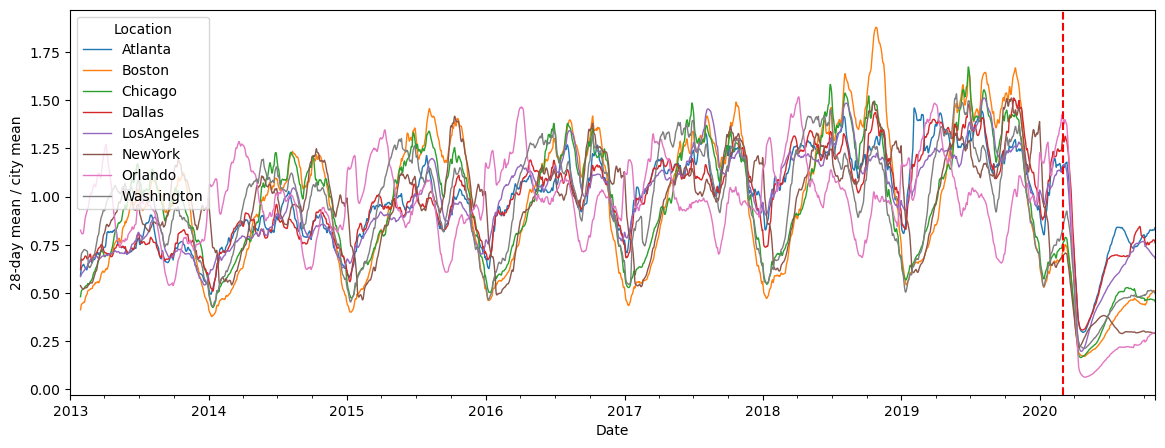

In [3]:
(rev / rev.loc[:'2019'].mean()).rolling(28).mean().plot(lw=1, figsize=(14, 5))
plt.axvline(COVID, c='r', ls='--'); plt.ylabel('28-day mean / city mean');

To compare the cities we use some forecastability indicators seen in class, computed on the pre-COVID period (2013-2019):
* **ACF at lag 7 and 364:** how much a day resembles the same weekday one week / one year before. Higher = stronger weekly / yearly pattern.
* **Variance ratio** $\operatorname{Var}(\Delta y_t) / \operatorname{Var}(y_t)$: how large the day-to-day changes are compared to the total variability. Lower = smoother series.
* **Spectral entropy** $H = -\frac{1}{\log K}\sum_i p_i \log p_i$ ($p_i$ = normalised periodogram): lower when the signal is dominated by a few periodicities.
* **MAPE of the weekly seasonal naive on 2019:** an a-posteriori check, i.e. how well the simplest seasonal forecaster actually works.

We choose the city with the lowest seasonal-naive error, because it is the measure closest to our actual task (short-term forecasting).

In [4]:
pre = rev.loc[:'2019']
def spec_entropy(s):
    p = periodogram(s - s.mean())[1][1:]           # drop the zero frequency
    p = p / p.sum()
    return -(p * np.log(p + 1e-12)).sum() / np.log(len(p))

snaive_mape = lambda s: (abs(s - s.shift(7)) / s).loc['2019'].mean() * 100
stats = pd.DataFrame({
    'ACF lag 7':   pre.apply(lambda s: s.autocorr(7)),
    'ACF lag 364': pre.apply(lambda s: s.autocorr(364)),
    'Var ratio':   pre.diff().var() / pre.var(),
    'Spec entropy': pre.apply(spec_entropy),
    'MAPE snaive7 2019 [%]': pre.apply(snaive_mape),
}).sort_values('MAPE snaive7 2019 [%]').round(3)

CITY = stats.index[0]
print('Selected city:', CITY)
stats

Selected city: LosAngeles


,ACF lag 7,ACF lag 364,Var ratio,Spec entropy,MAPE snaive7 2019 [%]
Location,,,,,
LosAngeles,0.826,0.920,0.352,0.450,12.119
Dallas,0.735,0.893,0.573,0.537,17.865
Orlando,0.559,0.807,0.380,0.567,19.292
NewYork,0.681,0.903,0.411,0.506,19.504
Atlanta,0.639,0.837,0.568,0.577,20.244
Boston,0.807,0.905,0.320,0.400,21.526
Washington,0.714,0.890,0.382,0.488,21.677
Chicago,0.698,0.901,0.475,0.457,22.337


**Observations:**
* All cities follow a similar path: growth until about 2017, a summer peak every year and the collapse in March 2020.
* Los Angeles has the strongest weekly pattern (ACF lag 7 = 0.83) and a much lower seasonal-naive error than any other city (12.1%, the second best is Dallas with 17.9%).
* On variance ratio and spectral entropy Boston is slightly better than LA (0.32 vs 0.35 and 0.40 vs 0.45). Boston has a very strong and smooth yearly cycle, which makes these two indicators look good, but this does not help to forecast 1-7 days ahead: its seasonal-naive error is 21.5%.
* A-priori indicators are a quick first screening, but the real test is how well a forecaster performs. We therefore choose **Los Angeles**, which is also among the top two on every indicator.
* The rest of the notebook only uses the variable `CITY`, so it can be rerun for any other city.

In [5]:
data = df[df['Location'] == CITY].drop(columns='Location').loc['2013':'2020'].asfreq('D')
y = data['Revenue']
y_pre = y.loc[:'2019-12-31']         # "regular" regime, used for analysis and model selection

### 2.2 Time plot

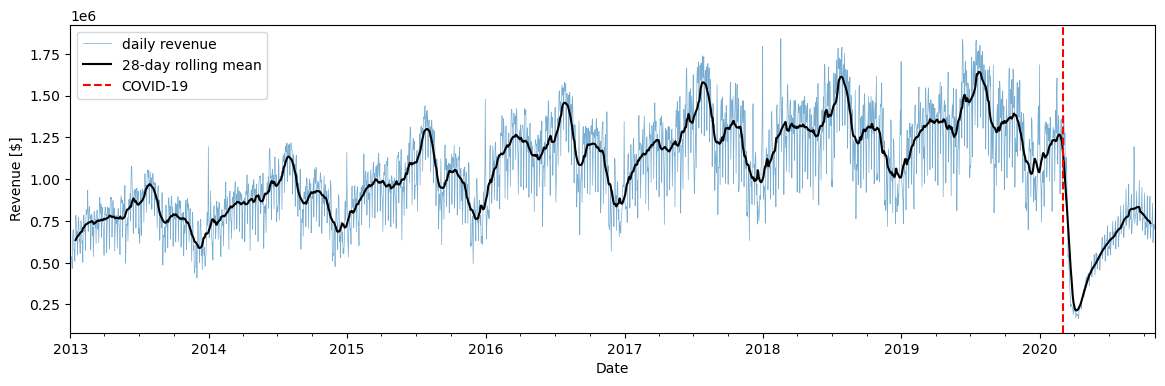

In [6]:
ax = y.plot(lw=0.5, alpha=0.6, label='daily revenue')
y.rolling(28, center=True).mean().plot(ax=ax, c='k', label='28-day rolling mean')
ax.axvline(COVID, c='r', ls='--', label='COVID-19')
ax.set_ylabel('Revenue [$]'); ax.legend();

**Observations:**
* Revenue grows from 2013 to 2017 and then stays roughly stable.
* Every year there is a peak in summer (July-August) and a drop at the end of the year.
* There is a strong weekly oscillation, and it becomes larger when the level is higher: the seasonality looks multiplicative.
* In March 2020 revenue falls by about 85% (to about 200k USD) because of COVID, and by October it has recovered only in part.

### 2.3 Calendar distributions
Boxplots by day of week and by month (pre-COVID only, to avoid mixing the two regimes).

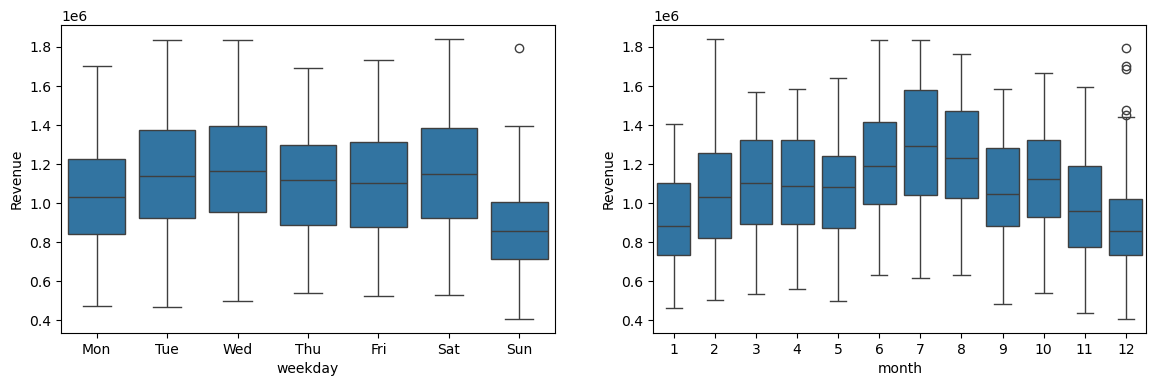

In [7]:
cal = pd.DataFrame({'Revenue': y_pre, 'weekday': y_pre.index.day_name().str[:3], 'month': y_pre.index.month})
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sb.boxplot(cal, x='weekday', y='Revenue', ax=ax[0], order=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
sb.boxplot(cal, x='month', y='Revenue', ax=ax[1]);

**Observations:**
* Weekly pattern: Sunday is the weakest day, followed by Monday; Tuesday, Wednesday and Saturday are the strongest.
* Yearly pattern: the high season is June-August, the low season January and December. The few high values in December are holidays.

### 2.4 Correlation with the other variables
`Demand` (rooms sold) and `Occupancy` are known only up to today, so they can be used as **lagged** exogenous features, not as same-day regressors.

           Revenue  Demand  Occupancy
Revenue       1.00    0.96       0.76
Demand        0.96    1.00       0.86
Occupancy     0.76    0.86       1.00


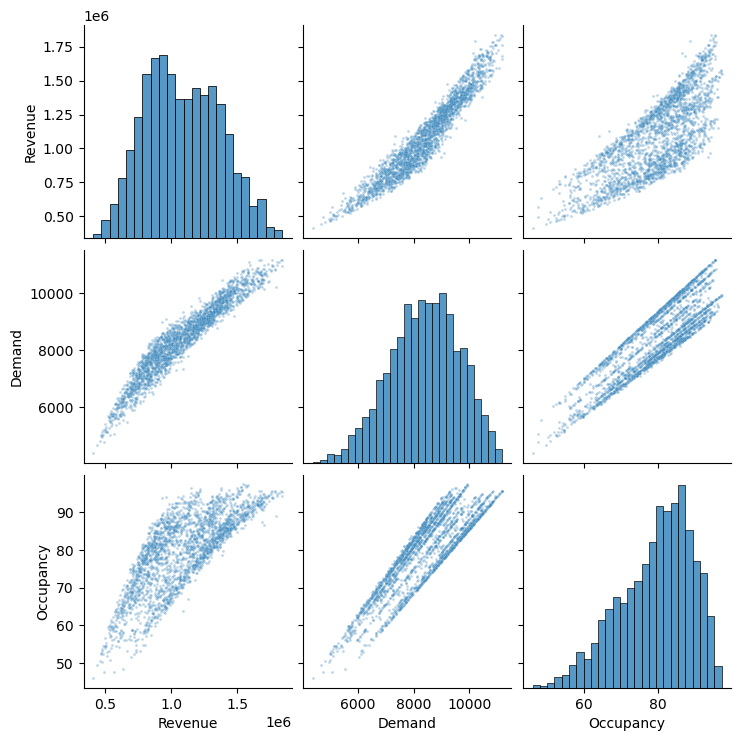

In [8]:
print(data.loc[:'2019'].corr().round(2))
sb.pairplot(data.loc[:'2019'], plot_kws=dict(s=4, alpha=0.3), height=2.5);

**Observations:**
* Revenue and Demand are almost perfectly correlated (correlation 0.96), which makes sense: revenue is roughly rooms sold times the average price. Occupancy is less correlated (0.76).
* Since the three variables move together, past values of Demand would add very little to past values of Revenue. We therefore build univariate models.

### 2.5 ACF / PACF
Short lags (weekly structure) and long lags (yearly structure, 364 = 52 weeks keeps the weekday aligned).

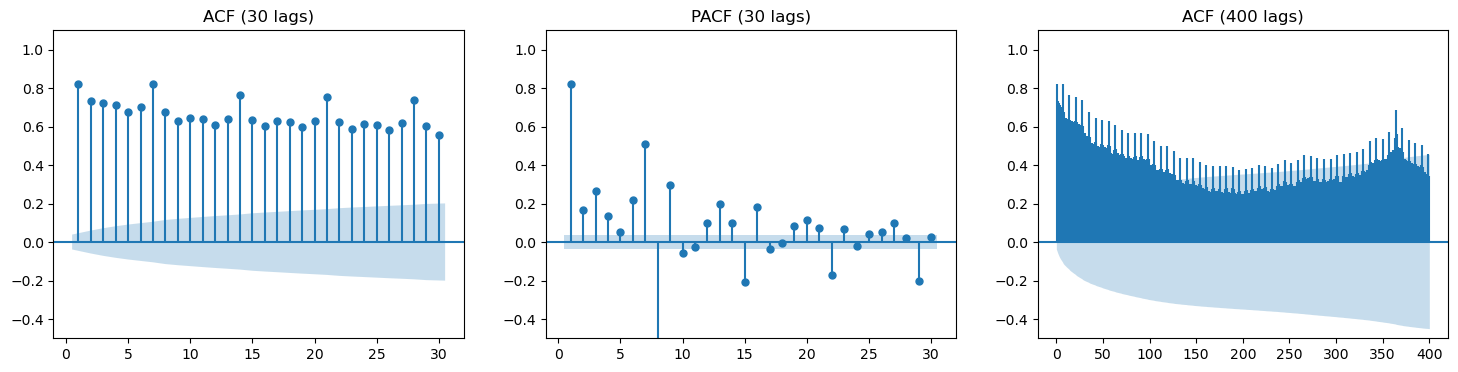

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
plot_acf(y_pre, lags=30, zero=False, ax=ax[0], title='ACF (30 lags)')
plot_pacf(y_pre, lags=30, zero=False, ax=ax[1], title='PACF (30 lags)')
plot_acf(y_pre, lags=400, zero=False, ax=ax[2], title='ACF (400 lags)', marker=None)
for a in ax: a.set_ylim(-0.5, 1.1)

**Observations:**
* The ACF decreases very slowly and has peaks at lags 7, 14, 21, 28: the series has a trend and a weekly seasonality, so it is not stationary.
* The PACF has a large spike at lag 1 and significant values around lags 7-9: this suggests a seasonal AR/MA structure with period 7.
* At long lags the ACF increases again around lag 364: there is also a yearly seasonality.

### 2.6 Decomposition
We use STL with two seasonal periods (MSTL) to separate trend, weekly (7) and yearly (365) seasonality. We decompose the log series, where the seasonal effects become additive (see 3.1).

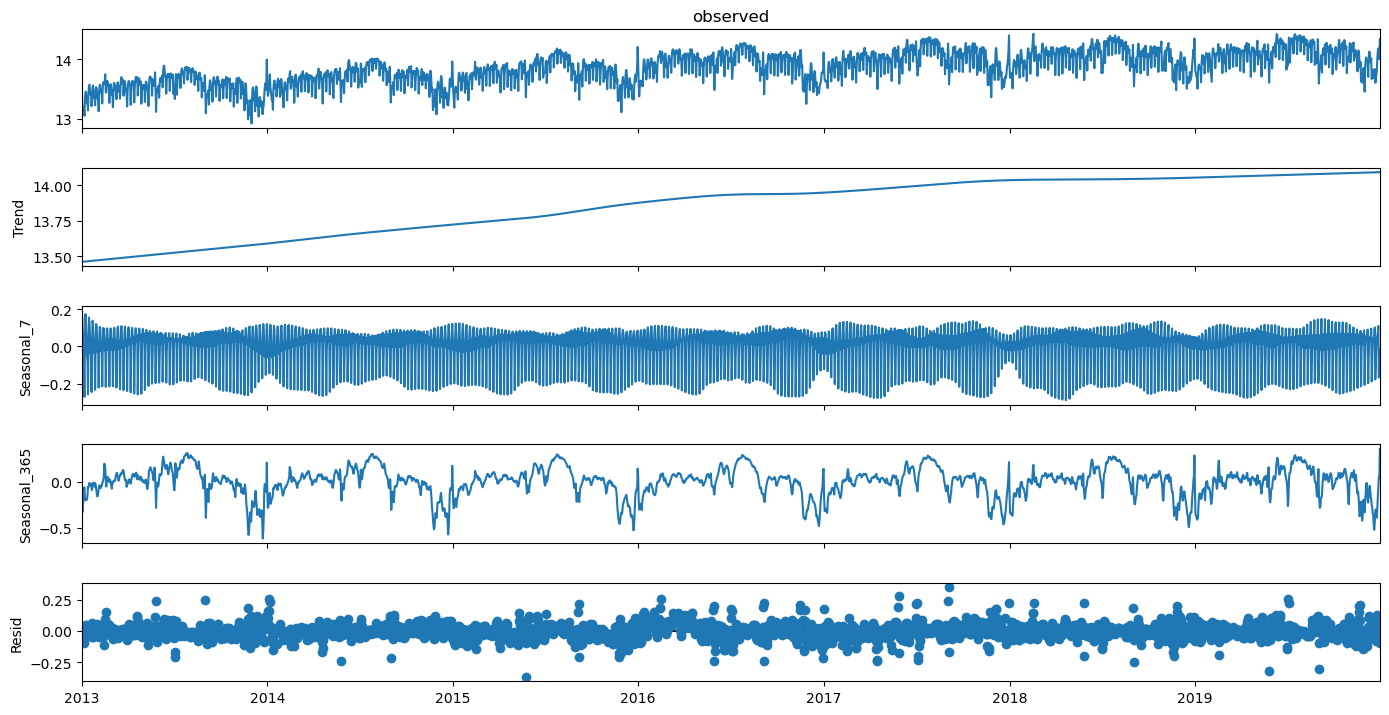

In [10]:
MSTL(np.log(y_pre), periods=(7, 365)).fit().plot().set_size_inches(14, 8)

## 3. Transformations and stationarity
### 3.1 Variance stabilisation
If the local standard deviation grows with the local level, a log / Box-Cox transform makes the variance (and the seasonal amplitude) roughly constant.

Box-Cox lambda (MLE) = 0.58   (0 = log)


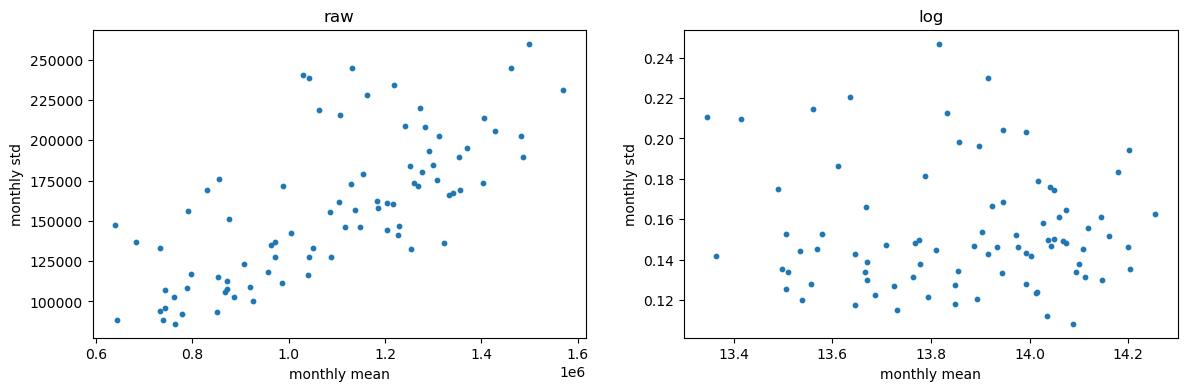

In [11]:
lam = boxcox(y_pre.values)[1]
print(f'Box-Cox lambda (MLE) = {lam:.2f}   (0 = log)')

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, s, name in zip(ax, [y_pre, np.log(y_pre)], ['raw', 'log']):
    r = s.resample('ME')                        # monthly mean vs monthly std
    a.scatter(r.mean(), r.std(), s=10)
    a.set(xlabel='monthly mean', ylabel='monthly std', title=name)

**Observations:**
* On the raw series the monthly standard deviation grows with the monthly mean: the variance is not constant.
* After taking the log the standard deviation no longer depends on the level, so the log solves the problem.
* The optimal Box-Cox lambda is 0.58, between the square root and the log. We use the log because it is simpler to interpret and to back-transform, and it works well here.

### 3.2 Stationarity tests
| Test | H0 | H1 |
|---|---|---|
| ADF | non-stationary (unit root) | stationary |
| KPSS | (level) stationary | non-stationary |

A series looks stationary when ADF p-value is small **and** KPSS p-value is large.

In [12]:
ly = np.log(y_pre)
candidates = {'y': y_pre, 'log y': ly,
              'diff7 log y': ly.diff(7), 'diff1 diff7 log y': ly.diff(7).diff()}
pd.DataFrame({k: {'adf pval': adfuller(s.dropna())[1], 'kpss pval': kpss(s.dropna())[1]}
              for k, s in candidates.items()}).T.round(3)

,adf pval,kpss pval
y,0.076,0.01
log y,0.083,0.01
diff7 log y,0.000,0.10
diff1 diff7 log y,0.000,0.10


**Observations:**
* `y` and `log y` are not stationary: ADF does not reject the unit root (p = 0.08) and KPSS rejects stationarity (p = 0.01).
* After one seasonal difference (`diff7 log y`) both tests agree that the series is stationary (ADF p < 0.001, KPSS p = 0.10). So for ARIMA on log y we expect $d=0$, $D=1$, $m=7$.
* **The log (or Box-Cox) does not make the series stationary.** It only stabilises the variance; trend and seasonality are still there and are removed by differencing.
* **Why stationarity matters:** we only have one realisation of the series, so we can estimate its mean and autocorrelation only by averaging over time. This makes sense only if the statistical properties do not change over time. ARIMA also requires a stationary series after differencing. 2020 shows what happens when this fails: after the break the past no longer describes the future, and all models get worse (section 6).

## 4. Cross-validation setup and baselines
### 4.1 How to handle COVID
The 2020 collapse is an external shock that no model trained on 2013-2019 could predict. For this reason:
* we **select the model** using cross-validation on **2019**, a normal year;
* we use **2020** only as a **stress test**, to see how each model reacts to the break.

### 4.2 Rolling-origin (expanding window) CV
For every day $t$ of the test period, the model only sees the data up to $t$ and forecasts $t+1, \dots, t+7$. This simulates how the forecast would be used in practice. The same function works for any forecaster `f(y_train, h)`, so baselines and models are evaluated in exactly the same way.

In [13]:
H = 7

def rolling_cv(y, forecaster, start, end, h=H, step=1):
    '''Expanding-window CV. Returns (y_true, y_hat), two DataFrames (origins x steps ahead).'''
    first, last = y.index.get_indexer([pd.Timestamp(start), pd.Timestamp(end)])
    origins = range(first, last - h + 1, step)
    y_hat = [forecaster(y.iloc[:t + 1], h) for t in origins]
    y_true = [y.iloc[t + 1:t + 1 + h].values for t in origins]
    idx, cols = y.index[list(origins)], range(1, h + 1)
    return pd.DataFrame(y_true, idx, cols), pd.DataFrame(y_hat, idx, cols)

### 4.3 Baselines
* **naive**: $\hat y_{T+h} = y_T$
* **mean**: $\hat y_{T+h} = \bar y$
* **seasonal naive (weekly)**: $\hat y_{T+h} = y_{T+h-7}$
* **seasonal naive (yearly)**: $\hat y_{T+h} = y_{T+h-364}$ (52 weeks, same weekday)

In [14]:
baselines = {
    'naive':     lambda y, h: np.repeat(y.iloc[-1], h),
    'mean':      lambda y, h: np.repeat(y.mean(), h),
    'snaive_7':  lambda y, h: np.resize(y.iloc[-7:].values, h),     # repeats the last week
    'snaive_364': lambda y, h: y.iloc[-364:-364 + h].values,         # same days, 52 weeks ago
}

cv = {name: rolling_cv(y, f, '2019-01-01', '2019-12-31') for name, f in baselines.items()}
stress = {name: rolling_cv(y, f, '2020-01-01', '2020-10-31') for name, f in baselines.items()}

### 4.4 Error metrics
* **MAE per step ahead**, to see how the error grows with the horizon.
* **nMAE**, as in the course: MAE over the 7-day window normalised by the std of the signal in that window, averaged over origins.
* **MAPE**, easy to communicate (revenue is always far from 0).

In [15]:
nmae = lambda yt, yh: (np.abs(yt - yh).mean(axis=1) / yt.std(axis=1)).mean()
mape = lambda yt, yh: (np.abs(yt - yh) / yt).values.mean() * 100

def scores(res):
    return pd.DataFrame({n: {'MAE': np.abs(yt - yh).values.mean(), 'nMAE': nmae(yt, yh), 'MAPE %': mape(yt, yh)}
                         for n, (yt, yh) in res.items()}).T.sort_values('MAE')

display(scores(cv).round(2))
display(scores(stress).round(2))

,MAE,nMAE,MAPE %
snaive_364,82579.94,0.51,6.45
snaive_7,142778.23,0.89,11.72
naive,189304.61,1.16,15.28
mean,295129.53,1.80,20.99


,MAE,nMAE,MAPE %
snaive_7,81762.18,1.22,13.69
naive,95479.75,1.23,13.61
mean,403859.65,11.34,96.23
snaive_364,640202.02,17.03,142.76


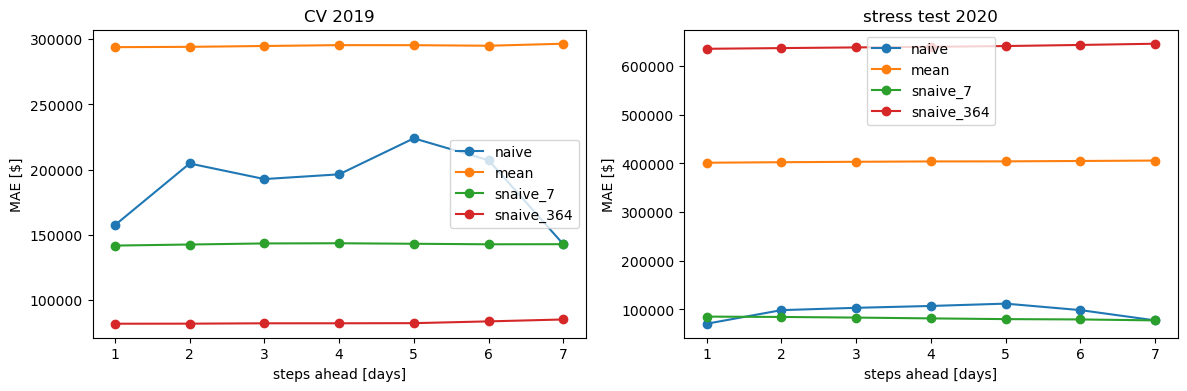

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, res, title in zip(ax, [cv, stress], ['CV 2019', 'stress test 2020']):
    pd.DataFrame({n: np.abs(yt - yh).mean() for n, (yt, yh) in res.items()}).plot(ax=a, marker='o')
    a.set(xlabel='steps ahead [days]', ylabel='MAE [$]', title=title)

**Observations:**
* **2019:** the best baseline is the yearly seasonal naive (MAE 82.6k USD, nMAE 0.51, MAPE 6.5%): the same weekday one year earlier already contains the weekly, yearly and holiday pattern. The weekly seasonal naive is second (MAE 142.8k USD, MAPE 11.7%). These are the results our models have to beat.
* The naive error goes up and down with the horizon because it ignores the weekly cycle; at $h=7$ it equals the weekly seasonal naive.
* **2020:** the ranking is reversed. Methods that look far back (yearly seasonal naive, mean) fail completely, while the naive and the weekly seasonal naive, which only use the last few days, adapt (MAPE about 13.7%). A good model should combine the seasonal patterns with the most recent level.

### 4.5 Residual check of the best baseline
If the 1-step-ahead errors are still autocorrelated, there is information left that a better model can exploit (Ljung-Box H0: no autocorrelation up to the given lag).

,lb_stat,lb_pvalue
7,302.790180,1.534032e-61
14,365.390824,2.420159e-69


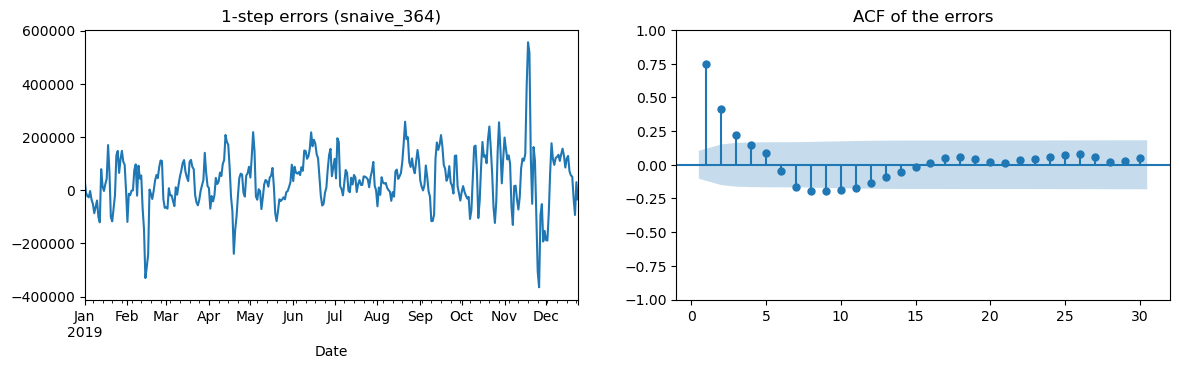

In [17]:
best = scores(cv).index[0]
e1 = cv[best][0][1] - cv[best][1][1]           # 1-step-ahead errors in 2019
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
e1.plot(ax=ax[0], title=f'1-step errors ({best})')
plot_acf(e1, lags=30, zero=False, ax=ax[1], title='ACF of the errors')
sm.stats.acorr_ljungbox(e1, lags=[7, 14])

**Observations:**
* The 1-day-ahead errors of the yearly seasonal naive are strongly autocorrelated (Ljung-Box p < 0.001): if this year is above last year on one day, it usually stays above for the following days.
* So the errors still contain information. A model that corrects last year's value using the most recent errors (for example an ARIMA on the errors) should do better.

## 5. Model building
### 5.1 Candidate models
All models are fitted on **log y** (section 3.1) with `statsforecast`; the orders and components are chosen automatically by AIC (its small-sample version, AICc).

| Model | Weekly season | Yearly season | Idea |
|---|---|---|---|
| **ETS** | $m=7$ | none | exponential smoothing of the level (and trend) and of the weekly pattern |
| **SARIMA** | $m=7$ | none | seasonal ARIMA; the tests in 3.2 suggest $D=1$ |
| **ARIMA + lag364** | $m=7$ | $\log y_{t-364}$ as regressor | last year's value, corrected by ARIMA errors (idea from 4.5) |

**Why lag364:** it is a time embedding (embeddings lecture): the value of the same weekday 52 weeks before is used as a feature, as in an ARIMAX model. It can also be seen as the yearly seasonal naive of 4.3, corrected by ARIMA errors. The regressor is known for the whole forecast horizon ($h \le 7 < 364$), so no information from the future is used.

In [18]:
lag364 = np.log(y).shift(364).values[:, None]     # NaN in 2013: this is why the estimation starts in 2014

models = {
    'ETS':              (AutoETS(season_length=7), None),
    'SARIMA':           (AutoARIMA(season_length=7), None),
    'ARIMA + lag364':   (AutoARIMA(season_length=7), lag364),
}

### 5.2 Fit and CV
To keep the notebook fast, the model parameters are **estimated only once**, on 2014-2018. During the CV the model is not refitted: at each day it is only **updated** with the new observations (same parameters, `forward` in statsforecast). Refitting at each of the ~650 origins would take tens of minutes and gives almost the same forecasts for 2019.

In [19]:
FIT = slice('2014-01-01', '2018-12-31')        # estimation window
s0 = y.index.get_loc(pd.Timestamp(FIT.start))

def sf_forecaster(model, X=None, y_fit=y):
    '''Fits a statsforecast model on log y_fit over FIT and returns f(y_train, h) to be used in rolling_cv.'''
    n_fit = len(y.loc[FIT])
    model.fit(np.log(y_fit.values[s0:s0 + n_fit]), X=None if X is None else X[s0:s0 + n_fit])
    def f(y_tr, h, level=None):
        n = len(y_tr)
        kw = {} if X is None else dict(X=X[s0:n], X_future=X[n:n + h])
        out = model.forward(y=np.log(y_tr.values[s0:]), h=h, level=level, **kw)
        # back-transform: exp of the log forecast (= median of the revenue forecast)
        return np.exp(out['mean']) if level is None else {k: np.exp(v) for k, v in out.items()}
    return f

forecasters = {n: sf_forecaster(m, X) for n, (m, X) in models.items()}
for n, (m, X) in models.items():
    print(f'{n:18s}', m.model_['method'] if n == 'ETS' else arima_string(m.model_))

for n, f in forecasters.items():
    cv[n] = rolling_cv(y, f, '2019-01-01', '2019-12-31')
    stress[n] = rolling_cv(y, f, '2020-01-01', '2020-10-31')

ETS                ETS(A,N,A)
SARIMA             ARIMA(5,0,2)(2,1,0)[7]                   
ARIMA + lag364     Regression with ARIMA(1,1,2)(2,0,0)[7] errors


**Observations:**
* **ETS(A,N,A):** no trend and an additive weekly season on the log scale, which corresponds to a multiplicative season on revenue (consistent with 3.1).
* **SARIMA(5,0,2)(2,1,0)[7]:** $d=0$, $D=1$, exactly what the stationarity tests in 3.2 suggested.
* **ARIMA + lag364**, with ARIMA(1,1,2)(2,0,0)[7] errors: the seasonal difference is no longer needed, because last year's value already brings the weekly and yearly pattern. The regular difference handles the slow change in the year-over-year ratio.

## 6. Results
### 6.1 Model selection (CV 2019) and stress test (2020)

In [20]:
res = pd.concat({'CV 2019': scores(cv), 'stress 2020': scores(stress)}, axis=1)
res.sort_values(('CV 2019', 'MAE')).style.format('{:,.2f}').highlight_min(color='lightgreen')

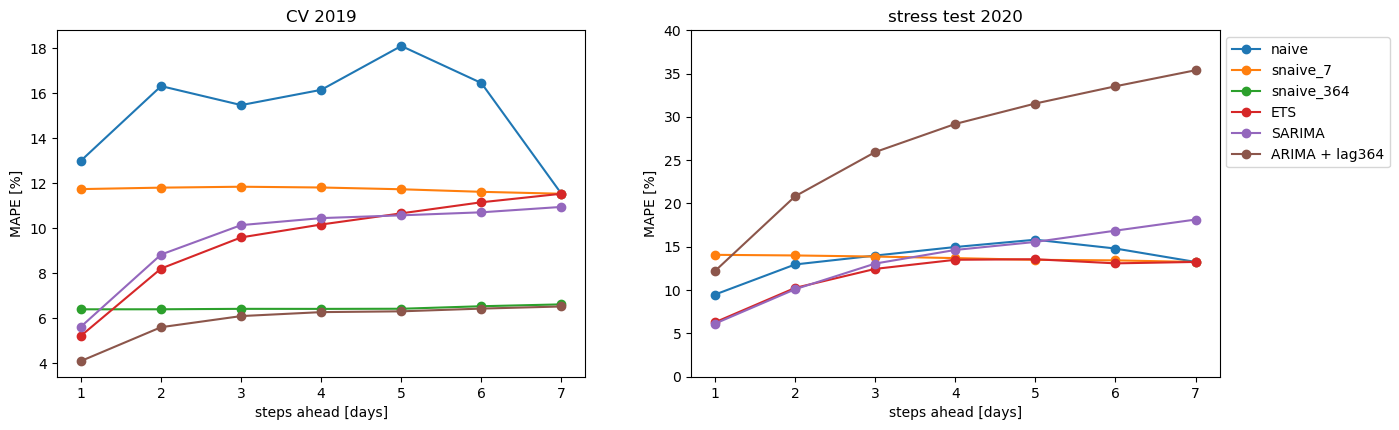

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, res_, title in zip(ax, [cv, stress], ['CV 2019', 'stress test 2020']):
    mape_h = pd.DataFrame({n: (np.abs(yt - yh) / yt).mean() * 100 for n, (yt, yh) in res_.items()})
    mape_h.drop(columns='mean').plot(ax=a, marker='o', legend=False)   # 'mean' is off the scale
    a.set(xlabel='steps ahead [days]', ylabel='MAPE [%]', title=title)
ax[1].set_ylim(0, 40); ax[1].legend(bbox_to_anchor=(1, 1));

**Observations:**
* **Selected model: ARIMA + lag364.** On 2019 it has the lowest error (MAE 73.7k USD, nMAE 0.46, MAPE 5.9%), 11% less MAE than the best baseline (yearly seasonal naive).
* The improvement is concentrated on the first days of the horizon (MAPE about 4% vs 6.4% at $h=1$), where the ARIMA part corrects last year's value using the recent errors. From $h \ge 4$ it is almost the same as the yearly seasonal naive.
* ETS and SARIMA are good at $h=1$ but get worse towards $h=7$ (about 11% MAPE): without yearly information they cannot do better than the weekly pattern.
* **2020:** the models that rely on the yearly pattern (yearly seasonal naive, and lag364 at longer horizons) fail, because last year no longer describes the new situation. ETS (MAPE 11.8%) and SARIMA (13.5%), which follow the recent level, are the most robust.

### 6.2 Residual diagnostics of the selected model
In-sample one-step residuals (log scale) on the estimation window: ideally uncorrelated, centred and roughly normal.

,lb_stat,lb_pvalue
7,7.752637,0.354911
14,21.493719,0.089633


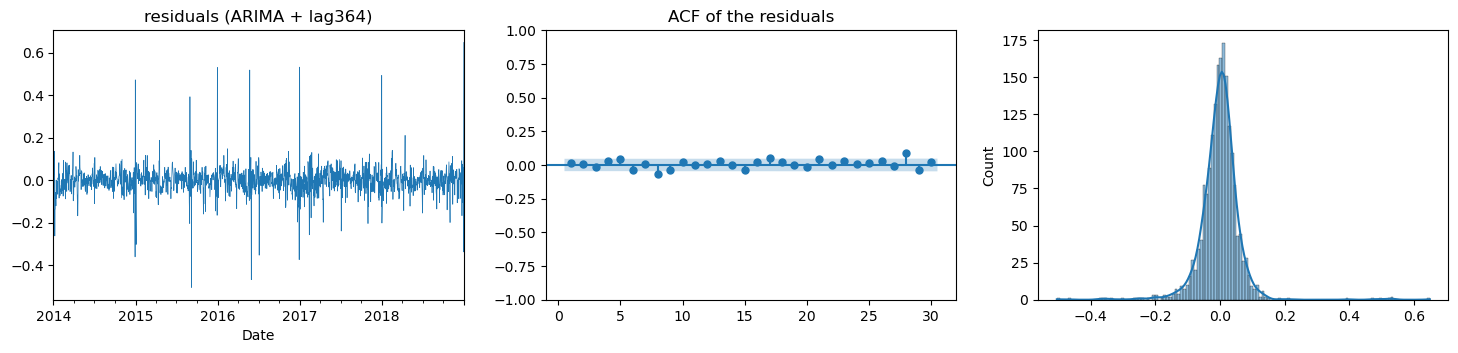

In [22]:
best = scores({n: cv[n] for n in models}).index[0]
m, X = models[best]
resid = pd.Series(np.log(y.loc[FIT].values) - m.predict_in_sample()['fitted'], y.loc[FIT].index)

fig, ax = plt.subplots(1, 3, figsize=(18, 3.5))
resid.plot(ax=ax[0], lw=0.5, title=f'residuals ({best})')
plot_acf(resid, lags=30, zero=False, ax=ax[1], title='ACF of the residuals')
sb.histplot(resid, kde=True, ax=ax[2])
sm.stats.acorr_ljungbox(resid, lags=[7, 14])

**Observations:**
* The residuals show no significant autocorrelation at lag 7 (Ljung-Box p = 0.35). At lag 14 the p-value is 0.09, borderline, so a small amount of structure may be left.
* The residuals are centred on zero but have heavy tails: there are isolated spikes, mostly on holidays. Moving holidays such as Thanksgiving are not captured by a 364-day lag.

### 6.3 Outlier treatment
**Why outliers matter:** they distort the estimated parameters and the choice of the model order, they make the residual variance (and so the prediction intervals) larger, and with `lag364` a spike from last year is copied into this year's forecast.

**Remove or impute?** In a time series we impute: removing a day would break the daily grid and shift the weekly and yearly lags.

We use the **Hampel filter** from the course on the MSTL remainder of log y, so that the normal seasonal peaks are not flagged. A day is an outlier if it is more than 3 standard deviations from the median of a centred 15-day window, and it is replaced by that median. We clean only the training data (up to 2018); the model is still evaluated on the real values.

outliers: 7 days (0.3%)


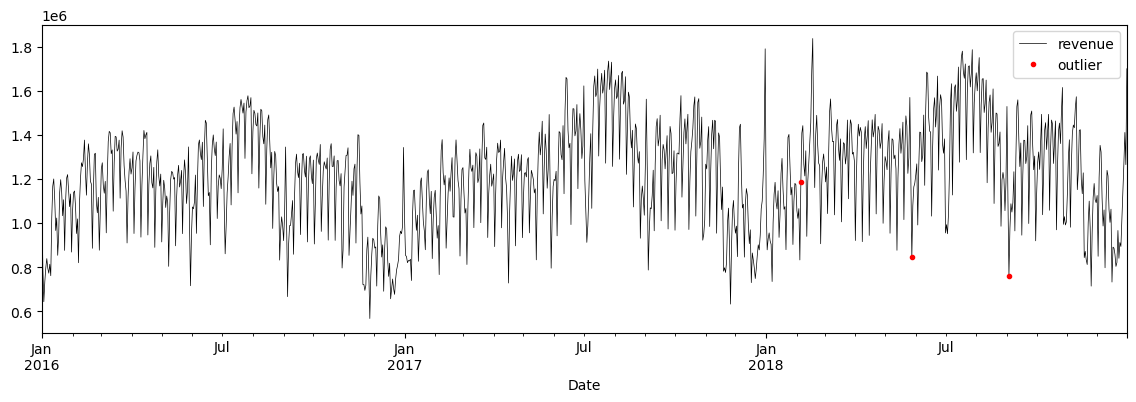

In [23]:
r = MSTL(np.log(y.loc[:'2018']), periods=(7, 365)).fit().resid
med = r.rolling(15, center=True, min_periods=1).median()
std = r.rolling(15, center=True, min_periods=1).std()
is_out = (r - med).abs() > 3 * std
out = is_out[is_out].index
y_clean = y.copy()
y_clean[out] = y[out] * np.exp(med - r)[out]          # remainder -> local median
print(f'outliers: {len(out)} days ({is_out.mean():.1%})')

ax = y.loc['2016':'2018'].plot(lw=0.5, c='k', label='revenue')
y[out].loc['2016':].plot(ax=ax, ls='', marker='o', c='r', ms=3, label='outlier')
ax.legend();

In [24]:
# same model, estimated on the cleaned series (also used for the lag-364 regressor)
lag364_clean = np.log(y_clean).shift(364).values[:, None]
f_clean = sf_forecaster(AutoARIMA(season_length=7), lag364_clean, y_clean)
name = best + ' (cleaned)'
cv[name] = rolling_cv(y, f_clean, '2019-01-01', '2019-12-31')
stress[name] = rolling_cv(y, f_clean, '2020-01-01', '2020-10-31')
pd.concat({'CV 2019': scores({n: cv[n] for n in [best, name]}),
           'stress 2020': scores({n: stress[n] for n in [best, name]})}, axis=1).round(2)

CV 2019              stress 2020             
                               MAE  nMAE MAPE %         MAE  nMAE MAPE %
ARIMA + lag364            73727.37  0.46   5.90   116198.57  2.73  26.95
ARIMA + lag364 (cleaned)  76136.13  0.47   6.17   112878.79  2.62  26.07

**Observations:**
* The filter flags only 7 days (0.3% of the training data), almost all holiday Mondays: Memorial Day (end of May) and Labor Day (beginning of September) weekends. Few days are flagged because a spike also increases the standard deviation of its own window.
* The model estimated on the cleaned data is slightly **worse** on 2019 (MAE 76.1k vs 73.7k USD, MAPE 6.2% vs 5.9%) and only slightly better on 2020 (MAPE 26.1% vs 27.0%).
* These holidays repeat every year but move by a few days, so `lag364` does not always align them. Replacing them with the median does not solve this: the model simply loses the information that these days are special. Dummies for moving holidays would be the right tool.
* We therefore keep the model estimated on the original data.

### 6.4 Example forecasts
7-days-ahead forecasts of the selected model with 80% / 95% prediction intervals, for a few origins in 2019.

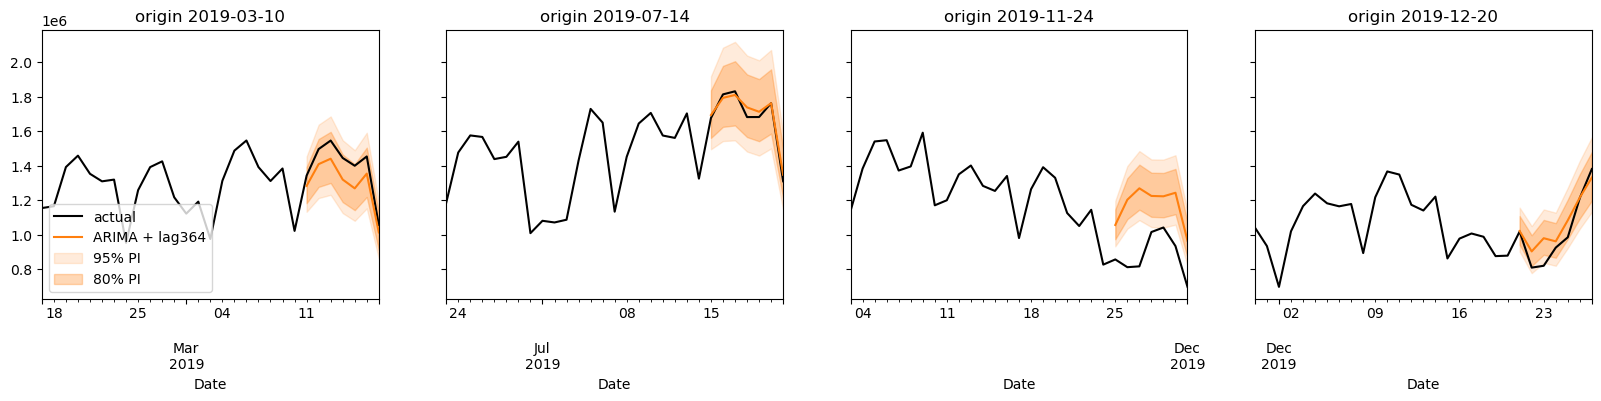

In [25]:
origins = ['2019-03-10', '2019-07-14', '2019-11-24', '2019-12-20']
fig, ax = plt.subplots(1, 4, figsize=(20, 3.5), sharey=True)
for a, o in zip(ax, origins):
    fc = forecasters[best](y.loc[:o], H, level=[80, 95])
    idx = pd.date_range(pd.Timestamp(o) + pd.Timedelta(days=1), periods=H)
    y.loc[pd.Timestamp(o) - pd.Timedelta(days=21):idx[-1]].plot(ax=a, c='k', label='actual')
    a.plot(idx, fc['mean'], c='C1', label=best)
    for lv, alpha in [(95, 0.15), (80, 0.3)]:
        a.fill_between(idx, fc[f'lo-{lv}'], fc[f'hi-{lv}'], color='C1', alpha=alpha, label=f'{lv}% PI')
    a.set_title(f'origin {o}')
ax[0].legend(loc='lower left');

### 6.5 Forecasts vs actual values and errors
1-day-ahead forecasts of the selected model over the whole CV (2019) and stress test (2020), with the forecast errors below.

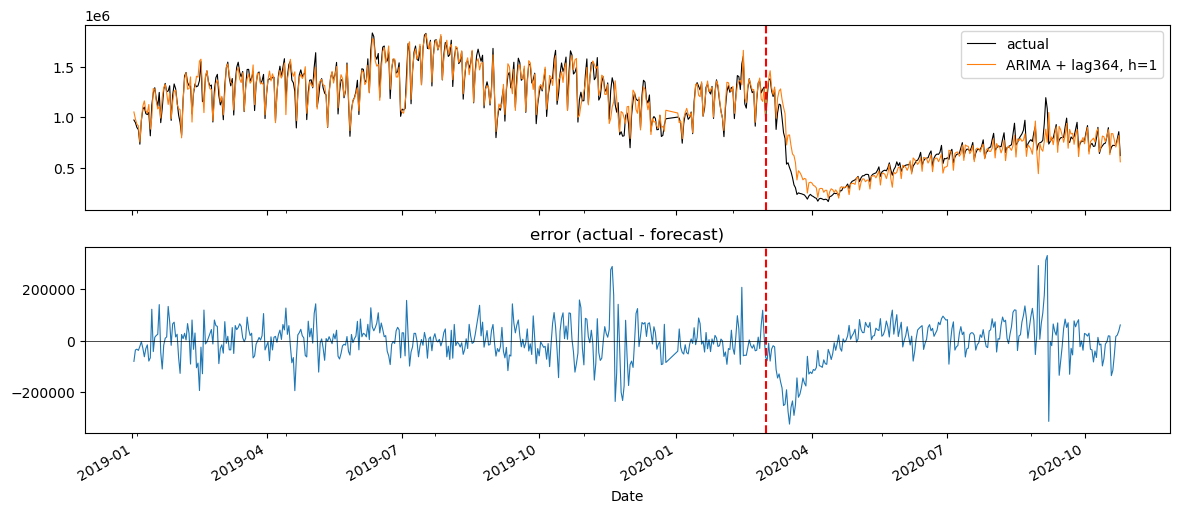

In [26]:
fc1 = pd.concat([cv[best][1][1], stress[best][1][1]])     # h = 1 forecasts, indexed by origin
fc1.index += pd.Timedelta(days=1)                          # ... re-indexed by target day
err = y[fc1.index] - fc1

fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
y[fc1.index].plot(ax=ax[0], c='k', lw=0.8, label='actual')
fc1.plot(ax=ax[0], c='C1', lw=0.8, label=f'{best}, h=1')
err.plot(ax=ax[1], lw=0.8, title='error (actual - forecast)')
for a in ax: a.axvline(COVID, c='r', ls='--')
ax[0].legend(); ax[1].axhline(0, c='k', lw=0.5);

**Observations:**
* In 2019 the forecast follows the actual revenue closely. The errors are centred on zero, with a few spikes around holidays (end of November, Christmas and New Year).
* In March 2020 the model keeps predicting the old level for a few days, so the errors become very large (down to about -300k USD). After about three weeks the model adapts to the new level and the errors return around zero.
* From summer 2020 the errors are centred again, but there are larger spikes when `lag364` repeats a 2019 pattern (for example a holiday) that does not happen during COVID.

### 6.6 Conclusions
* **Selected model:** log revenue explained by its value 52 weeks earlier, with ARIMA(1,1,2)(2,0,0)[7] errors. In a normal year (2019) it forecasts 1-7 days ahead with MAE 73.7k USD (MAPE 5.9%, about 4% at one day). It beats all baselines and the other models, and its residuals show no significant autocorrelation at lag 7.
* **Weak points:**
  * moving holidays: Thanksgiving 2019 falls on a normal day of 2018, so last year's value is wrong;
  * structural breaks: after March 2020 last year's value is misleading and the error goes up to MAPE 27%.
* **What we learned:**
  * removing outliers (Hampel filter) did not help: the flagged days are moving holidays, which need dummies rather than cleaning;
  * no single model is best in every situation: lag364 is the best in a stable period, ETS is the most robust after a break.
* **In practice:** use ARIMA + lag364 in normal conditions and monitor its errors. After a break, switch to a model that follows the recent level (ETS) until enough new data is available.
* **Possible improvements:** dummies for moving holidays, re-estimating the parameters after a break, an average of ETS and ARIMA + lag364.